# Experiment 11: flat-type segmented models

Train a global rental model and separate AutoGluon models for each sufficiently large `FLAT_TYPE`. At prediction time, each row is routed to its flat-type model; sparse or unseen types fall back to the global model. Validation is chronological.

In [7]:
from pathlib import Path
import json, os, sys
import numpy as np
import pandas as pd
from autogluon.common import space
from autogluon.tabular import TabularPredictor
from scipy.spatial import cKDTree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

configured_root = os.environ.get('KDDM_PROJECT_ROOT')
candidate_roots = ([Path(configured_root)] if configured_root else []) + [Path.cwd(), *Path.cwd().parents, Path('/content/KDDM-project'), Path('/content/drive/MyDrive/KDDM-project')]
project_root = next((p for p in candidate_roots if (p / 'exploration/metul/preprocessing.py').exists()), None)
if project_root is None: raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')
experiment_dir = project_root / 'exploration' / 'metul'
sys.path.insert(0, str(experiment_dir))
from preprocessing import RentalPreprocessor, load_datasets

TARGET, GROUP_COLUMNS, LAG_MONTHS = 'MONTHLY_RENT', ['TOWN', 'FLAT_TYPE'], 24
RUN_ID = os.environ.get('AUTOGLUON_RUN_ID', pd.Timestamp.now().strftime('%Y%m%d_%H%M%S'))
HPO_TIME_LIMIT_PER_SEGMENT = int(os.environ.get('SEGMENT_HPO_TIME_LIMIT', '900'))
HPO_TRIALS_PER_MODEL = int(os.environ.get('SEGMENT_HPO_TRIALS', '10'))
MIN_SEGMENT_TRAIN_ROWS = int(os.environ.get('MIN_SEGMENT_TRAIN_ROWS', '2000'))
compact_features = ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'approval_date_num', 'approval_month', 'coe_quota_premium_mean', 'YEAR_COMPLETED', 'MAX_FLOOR', 'mrt_dist_nearest_km', 'mall_dist_nearest_km']
MODEL_FEATURES = compact_features + ['monthly_target_lag', 'town_flat_type_target_mean', 'nearest_mrt_name', 'nearest_tourist_attraction_name', 'nearest_monument_name']
HPO_HYPERPARAMETERS = {
    'GBM': {'num_leaves': space.Int(16, 500), 'num_iterations': space.Int(500, 1000), 'learning_rate': space.Real(0.01, 0.20, log=True), 'min_data_in_leaf': space.Int(10, 100), 'feature_fraction': space.Real(0.6, 1.0)},
    'CAT': {'iterations': space.Int(500, 1000), 'depth': space.Int(4, 10), 'learning_rate': space.Real(0.01, 0.20, log=True), 'l2_leaf_reg': space.Real(1.0, 20.0, log=True)},
}
HPO_KWARGS = {'num_trials': HPO_TRIALS_PER_MODEL, 'scheduler': 'local', 'searcher': 'random'}

_, datasets = load_datasets(project_root / 'data')
raw_train = datasets['train'].copy()
raw_train['period'] = pd.to_datetime(raw_train['RENT_APPROVAL_DATE'] + '-01').dt.to_period('M')
periods = np.sort(raw_train['period'].unique())
validation_cutoff = periods[int(len(periods) * 0.80)]
raw_fit = raw_train.loc[raw_train.period < validation_cutoff].copy()
raw_valid = raw_train.loc[raw_train.period >= validation_cutoff].copy()
print(f'Chronological cutoff: {validation_cutoff}; fit={len(raw_fit):,}, validation={len(raw_valid):,}; min segment size={MIN_SEGMENT_TRAIN_ROWS:,}; HPO={HPO_TRIALS_PER_MODEL} trials/model/segment')


Chronological cutoff: 2024-05; fit=117,988, validation=32,012; min segment size=2,000; HPO=10 trials/model/segment


In [8]:
class TargetFeatureTransformer:
    def __init__(self, lag_months=LAG_MONTHS): self.lag_months = lag_months
    def fit(self, history):
        self.global_mean_ = history[TARGET].mean()
        self.group_mean_ = history.groupby(GROUP_COLUMNS)[TARGET].mean()
        self.monthly_mean_ = history.groupby('period')[TARGET].mean()
        self.group_period_ = history.groupby(GROUP_COLUMNS + ['period'], as_index=False)[TARGET].mean().rename(columns={'period':'source_period', TARGET:'town_flat_type_target_lag'})
        return self
    def transform(self, history):
        result = history[GROUP_COLUMNS + ['period']].copy()
        result['monthly_target_lag'] = (result.period - self.lag_months).map(self.monthly_mean_).fillna(self.global_mean_)
        result['source_period'] = result.period - self.lag_months
        result = result.merge(self.group_period_, on=GROUP_COLUMNS + ['source_period'], how='left').drop(columns='source_period')
        group_mean = pd.Series(result.set_index(GROUP_COLUMNS).index.map(self.group_mean_), index=result.index)
        result['town_flat_type_target_mean'] = group_mean.fillna(self.global_mean_)
        result['town_flat_type_target_lag'] = result.town_flat_type_target_lag.fillna(result.town_flat_type_target_mean)
        return result[['monthly_target_lag', 'town_flat_type_target_mean', 'town_flat_type_target_lag']]
    def fit_transform_train(self, history):
        self.fit(history)
        grouped = history.groupby(GROUP_COLUMNS + ['period'], as_index=False)[TARGET].agg(['sum','count']).reset_index().sort_values(GROUP_COLUMNS + ['period'])
        grouped['prior_sum'] = grouped.groupby(GROUP_COLUMNS)['sum'].cumsum() - grouped['sum']
        grouped['prior_count'] = grouped.groupby(GROUP_COLUMNS)['count'].cumsum() - grouped['count']
        grouped['town_flat_type_target_mean'] = grouped.prior_sum / grouped.prior_count.replace(0, np.nan)
        global_monthly = history.groupby('period')[TARGET].agg(['sum','count']).sort_index()
        global_prior = (global_monthly['sum'].cumsum()-global_monthly['sum']) / (global_monthly['count'].cumsum()-global_monthly['count']).replace(0, np.nan)
        result = history[GROUP_COLUMNS + ['period']].merge(grouped[GROUP_COLUMNS + ['period','town_flat_type_target_mean']], on=GROUP_COLUMNS + ['period'], how='left')
        result['town_flat_type_target_mean'] = result.town_flat_type_target_mean.fillna(result.period.map(global_prior))
        result['source_period'] = result.period - self.lag_months
        result = result.merge(self.group_period_, on=GROUP_COLUMNS + ['source_period'], how='left').drop(columns='source_period')
        result['town_flat_type_target_lag'] = result.town_flat_type_target_lag.fillna(result.town_flat_type_target_mean)
        result['monthly_target_lag'] = (result.period-self.lag_months).map(self.monthly_mean_).fillna(result.period.map(global_prior))
        return result[['monthly_target_lag', 'town_flat_type_target_mean', 'town_flat_type_target_lag']]

def preprocess_partition(preprocessor, frame, fit=False):
    values = frame.drop(columns=['period', TARGET], errors='ignore')
    return preprocessor.fit_transform(values) if fit else preprocessor.transform(values)
def history_from(frame, base):
    result = base[GROUP_COLUMNS].reset_index(drop=True).copy(); result['period'] = frame.period.to_numpy(); result[TARGET] = frame[TARGET].to_numpy(); return result
def nearest_mrt_name(base):
    stations = datasets['mrt'][['NAME','LATITUDE','LONGITUDE']].dropna()
    _, index = cKDTree(stations[['LATITUDE','LONGITUDE']].to_numpy()*[111.0,110.96]).query(base[['LATITUDE','LONGITUDE']].to_numpy()*[111.0,110.96])
    return pd.Series(stations.NAME.astype(object).to_numpy()[index], name='nearest_mrt_name')
def nearest_geojson_name(base, filename, name_field, feature_name):
    with (project_root / 'data' / 'possible_additional_features' / filename).open() as handle: data = json.load(handle)
    points = pd.DataFrame([{'longitude':f['geometry']['coordinates'][0], 'latitude':f['geometry']['coordinates'][1], feature_name:f['properties'][name_field]} for f in data['features'] if f.get('geometry',{}).get('type') == 'Point']).dropna()
    _, index = cKDTree(points[['longitude','latitude']].to_numpy()*[110.96,111.0]).query(base[['LONGITUDE','LATITUDE']].to_numpy()*[110.96,111.0])
    return pd.Series(points[feature_name].astype(object).to_numpy()[index], name=feature_name)


In [9]:
# Fit every transformer on raw_fit only; validation is transform-only.
preprocessor = RentalPreprocessor(datasets)
fit_base = preprocess_partition(preprocessor, raw_fit, fit=True)
valid_base = preprocess_partition(preprocessor, raw_valid)
target_transformer = TargetFeatureTransformer()
fit_target = target_transformer.fit_transform_train(history_from(raw_fit, fit_base))
valid_target = target_transformer.transform(history_from(raw_valid, valid_base))
def make_model_frame(base, target_features):
    return pd.concat([base[compact_features].reset_index(drop=True), target_features.reset_index(drop=True), nearest_mrt_name(base).reset_index(drop=True), nearest_geojson_name(base, 'TouristAttractions.geojson', 'PAGETITLE', 'nearest_tourist_attraction_name').reset_index(drop=True), nearest_geojson_name(base, 'MonumentsGEOJSON.geojson', 'NAME', 'nearest_monument_name').reset_index(drop=True)], axis=1)[MODEL_FEATURES]
fit_x, valid_x = make_model_frame(fit_base, fit_target), make_model_frame(valid_base, valid_target)
fit_y, valid_y = raw_fit[TARGET].astype(float).reset_index(drop=True), raw_valid[TARGET].astype(float).reset_index(drop=True)
assert len(fit_x) == len(fit_y) and len(valid_x) == len(valid_y)


[categorical_clean] HDB lookup | TOWN: 26 -> 26 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | BLOCK: 2735 -> 2735 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | STREET: 576 -> 576 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | POSTAL_CODE: 9180 -> 9180 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | SUBZONE: 156 -> 156 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | PLANNING_AREA: 31 -> 31 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces


In [10]:
coverage = pd.DataFrame({'fit_rows': fit_x.groupby('FLAT_TYPE').size(), 'validation_rows': valid_x.groupby('FLAT_TYPE').size()}).fillna(0).astype(int)
coverage['train_segment_model'] = coverage.fit_rows >= MIN_SEGMENT_TRAIN_ROWS
display(coverage.sort_values('fit_rows', ascending=False))
eligible_flat_types = coverage.index[coverage.train_segment_model].tolist()
print('Eligible segment models:', eligible_flat_types)


,fit_rows,validation_rows,train_segment_model
FLAT_TYPE,,,
4 room,42401,11678,True
3 room,38440,10584,True
5 room,28253,7270,True
executive,6620,1614,True
2 room,2242,856,True
1 room,32,10,False


Eligible segment models: ['2 room', '3 room', '4 room', '5 room', 'executive']


## Numeric correlation by flat-type segment

These Pearson correlations use only the chronological training partition. Categorical variables are intentionally excluded; `MONTHLY_RENT` is included as the final column.

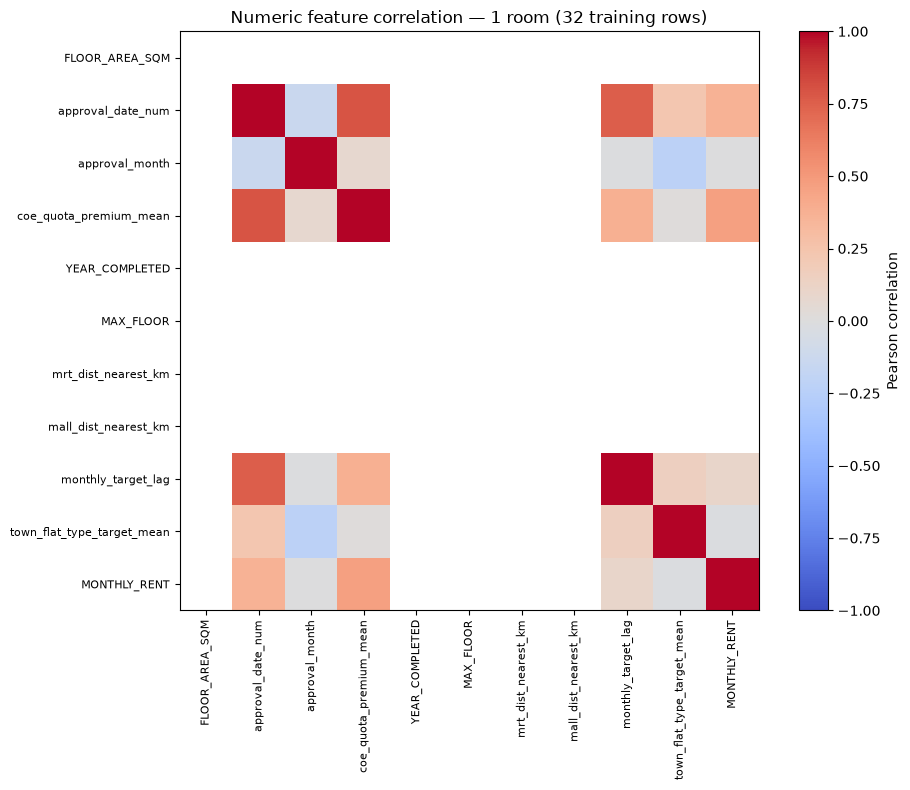

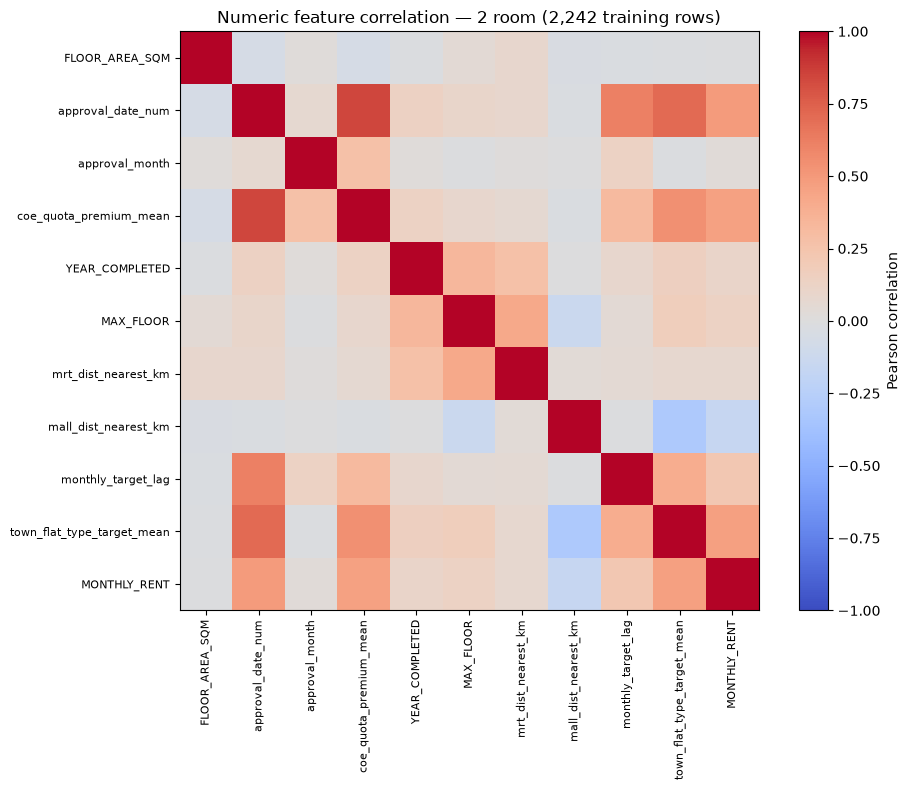

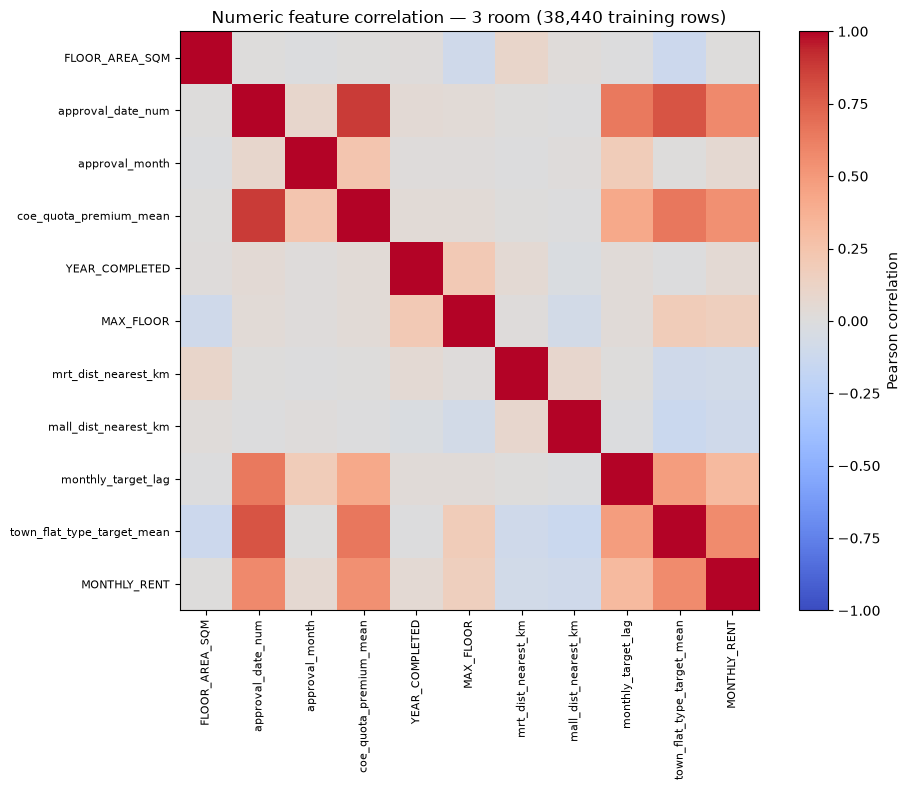

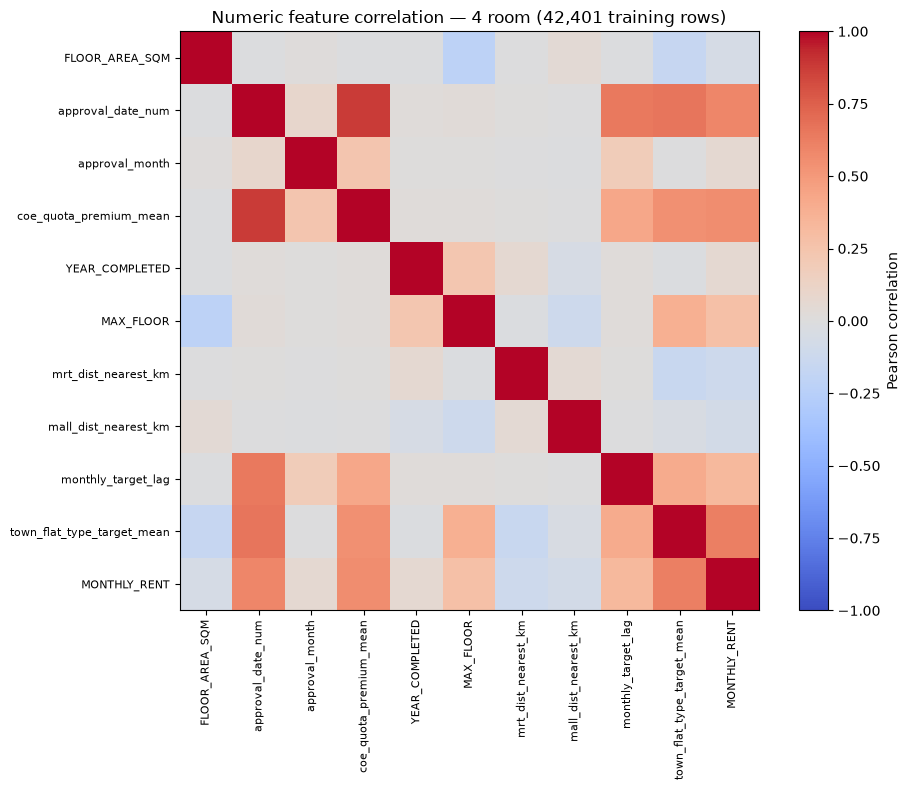

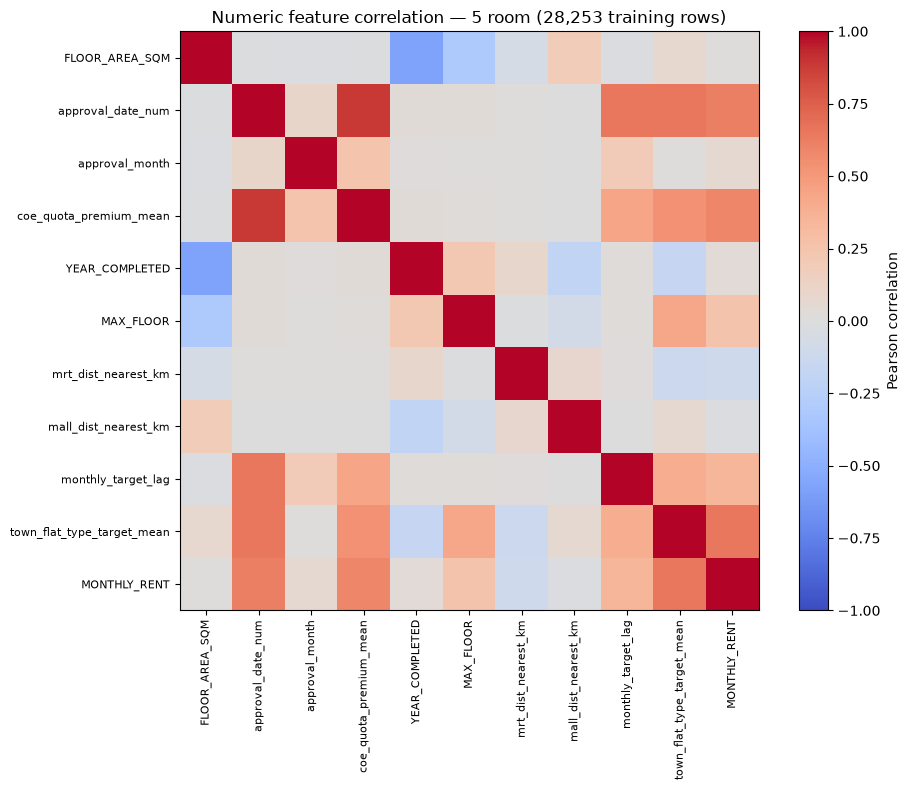

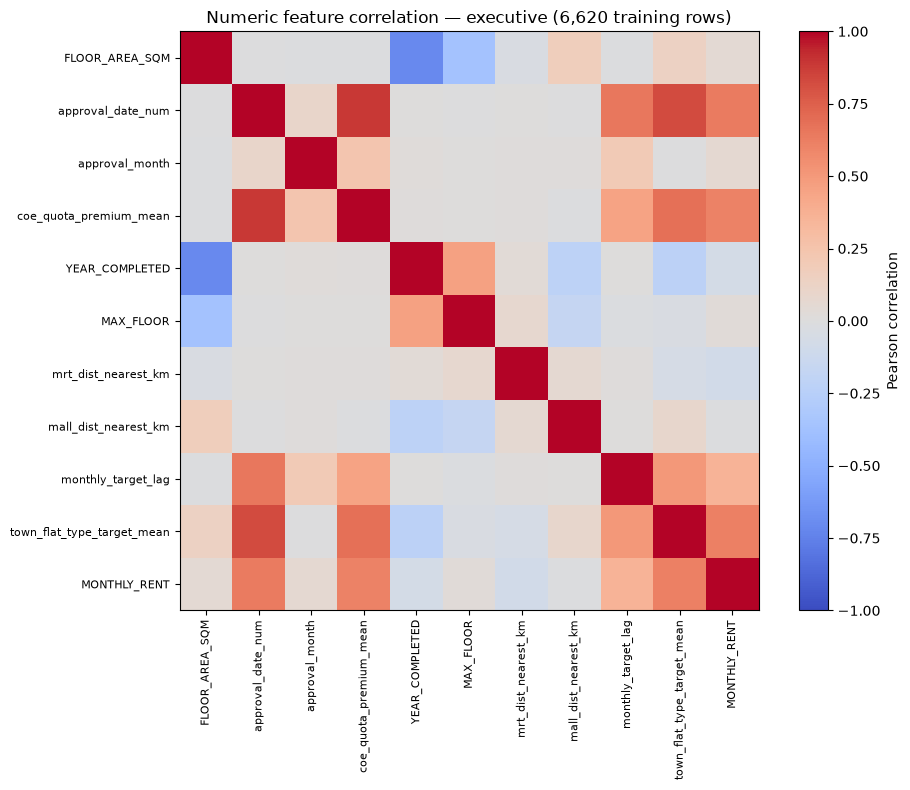

In [11]:
import matplotlib.pyplot as plt

numeric_feature_columns = fit_x.select_dtypes(include=np.number).columns.tolist()
for flat_type in sorted(fit_x['FLAT_TYPE'].dropna().unique()):
    segment_mask = fit_x['FLAT_TYPE'].eq(flat_type)
    correlation_frame = fit_x.loc[segment_mask, numeric_feature_columns].reset_index(drop=True).copy()
    correlation_frame[TARGET] = fit_y.loc[segment_mask].reset_index(drop=True)
    correlation = correlation_frame.corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(max(10, len(correlation.columns) * 0.7), max(8, len(correlation.columns) * 0.6)))
    image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(correlation.columns)), correlation.columns, fontsize=8)
    ax.set_title(f'Numeric feature correlation — {flat_type} ({segment_mask.sum():,} training rows)')
    fig.colorbar(image, ax=ax, label='Pearson correlation')
    fig.tight_layout()
    plt.show()


## Nonlinear relationship diagnostics

For each segment: Spearman captures monotonic relationships, mutual information captures broader dependence, and distance correlation provides an additional non-linear dependence check. All use training rows only.


1 room: numeric nonlinear-dependence ranking


,feature,spearman,mutual_information,distance_correlation,abs_spearman
0,coe_quota_premium_mean,0.476757,0.065306,0.508265,0.476757
1,approval_date_num,0.333334,0.059240,0.433268,0.333334
2,town_flat_type_target_mean,0.076867,0.000000,0.262072,0.076867
3,monthly_target_lag,0.045111,0.000000,0.204159,0.045111
4,approval_month,-0.042047,0.000000,0.170648,0.042047


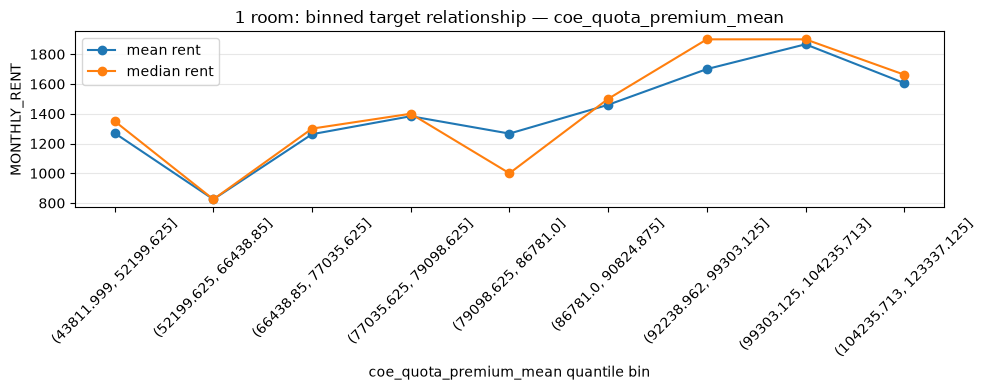

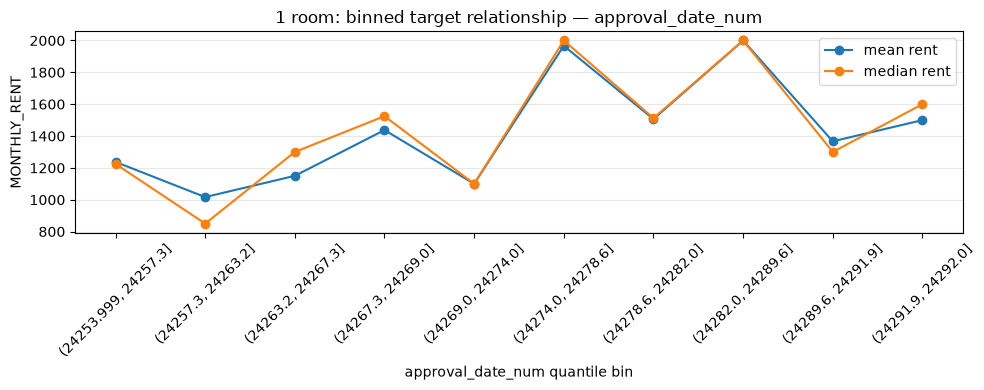

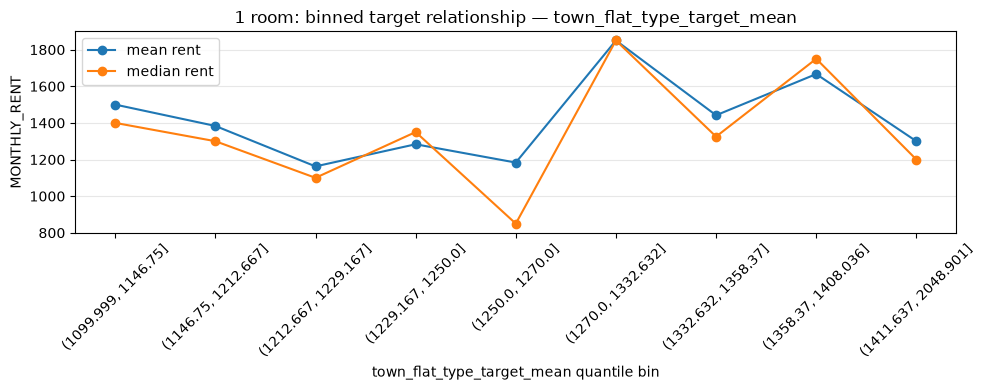

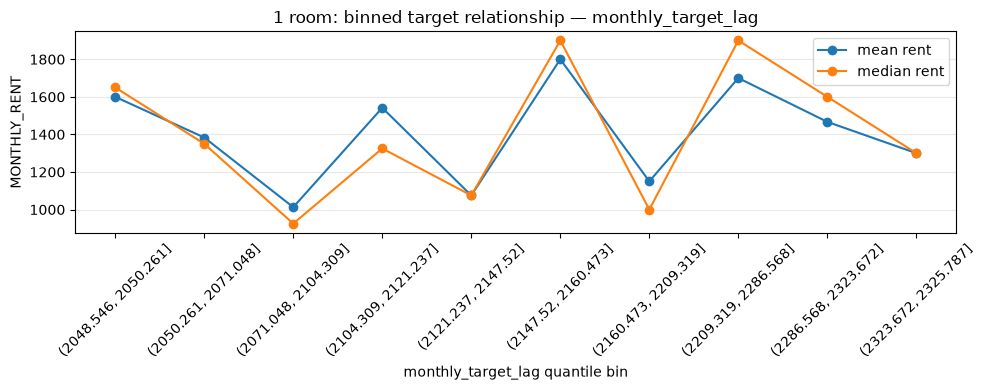

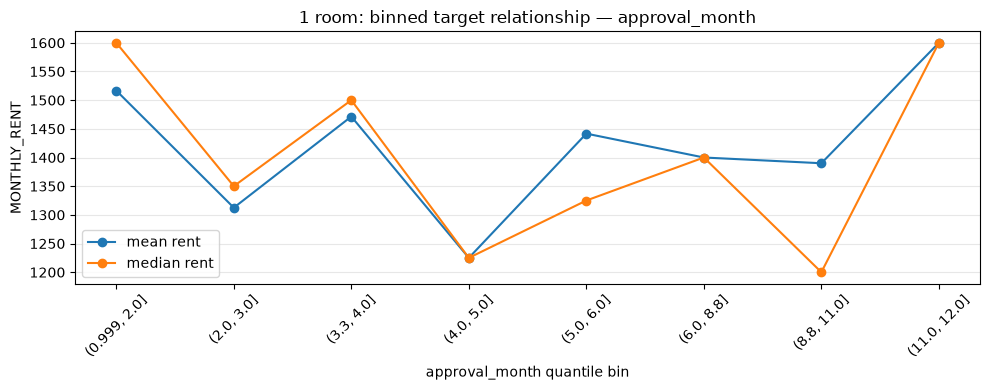


2 room: numeric nonlinear-dependence ranking


,feature,spearman,mutual_information,distance_correlation,abs_spearman
0,approval_date_num,0.500066,0.250298,0.543165,0.500066
1,coe_quota_premium_mean,0.465151,0.245133,0.507096,0.465151
2,town_flat_type_target_mean,0.508629,0.229993,0.504248,0.508629
3,monthly_target_lag,0.247728,0.175787,0.275348,0.247728
4,mall_dist_nearest_km,-0.160585,0.126571,0.146638,0.160585
5,YEAR_COMPLETED,0.248422,0.111178,0.247185,0.248422
6,mrt_dist_nearest_km,0.076790,0.106554,0.109898,0.076790
7,FLOOR_AREA_SQM,0.058067,0.094124,0.119925,0.058067
8,MAX_FLOOR,0.187591,0.078283,0.179619,0.187591
9,approval_month,0.034596,0.002498,0.043971,0.034596


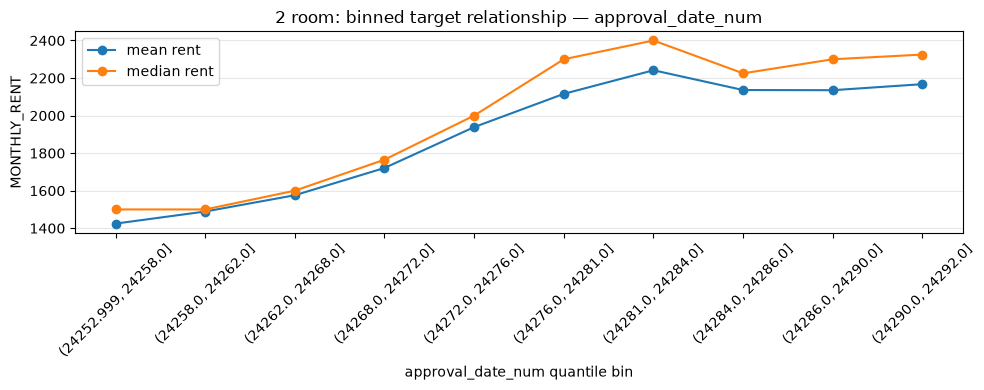

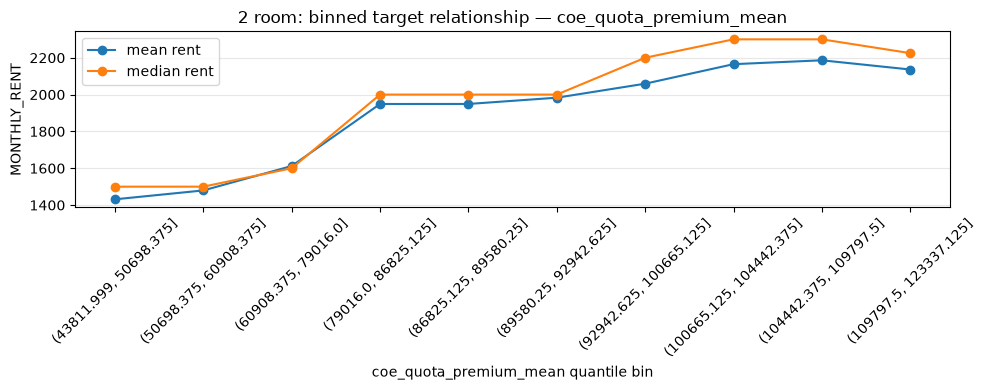

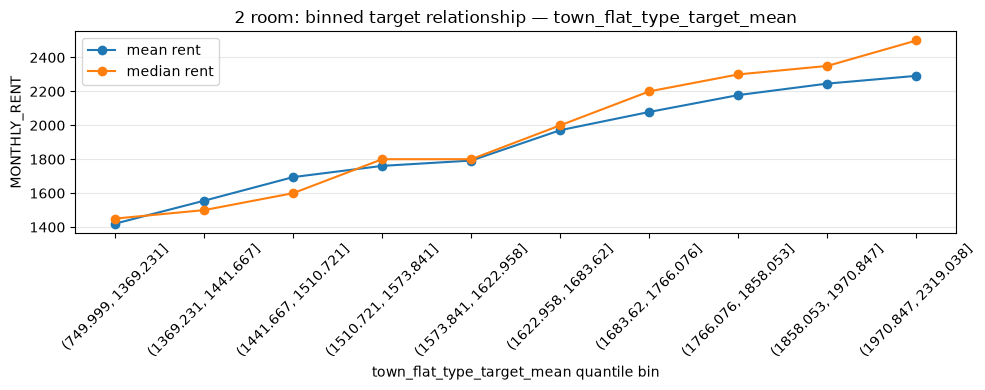

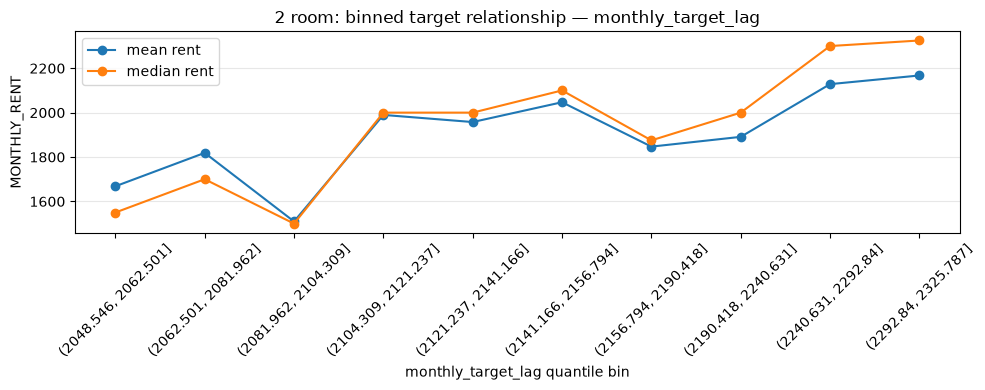

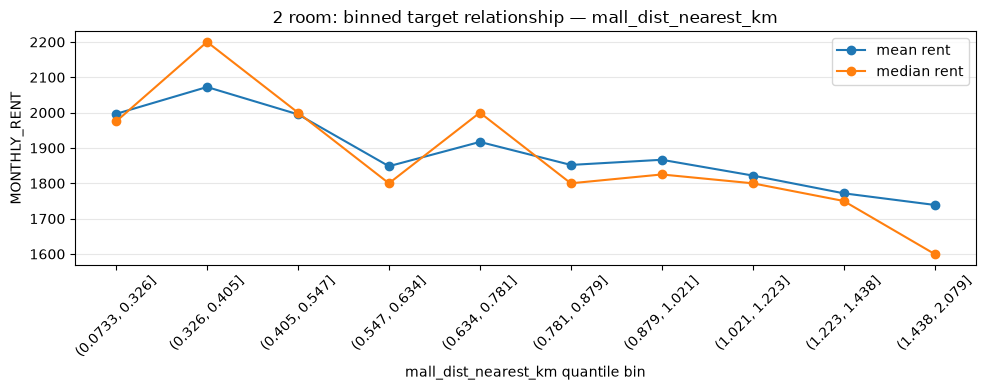


3 room: numeric nonlinear-dependence ranking


,feature,spearman,mutual_information,distance_correlation,abs_spearman
0,town_flat_type_target_mean,0.589755,0.281614,0.542698,0.589755
1,approval_date_num,0.585630,0.272152,0.601413,0.585630
2,coe_quota_premium_mean,0.550712,0.265168,0.568269,0.550712
3,monthly_target_lag,0.334437,0.234987,0.344689,0.334437
4,mrt_dist_nearest_km,-0.098849,0.091431,0.065659,0.098849
5,mall_dist_nearest_km,-0.103400,0.089662,0.129101,0.103400
6,YEAR_COMPLETED,-0.005517,0.033836,0.116926,0.005517
7,MAX_FLOOR,0.119065,0.029660,0.153044,0.119065
8,FLOOR_AREA_SQM,-0.016033,0.015796,0.038167,0.016033
9,approval_month,0.061377,0.008463,0.088320,0.061377


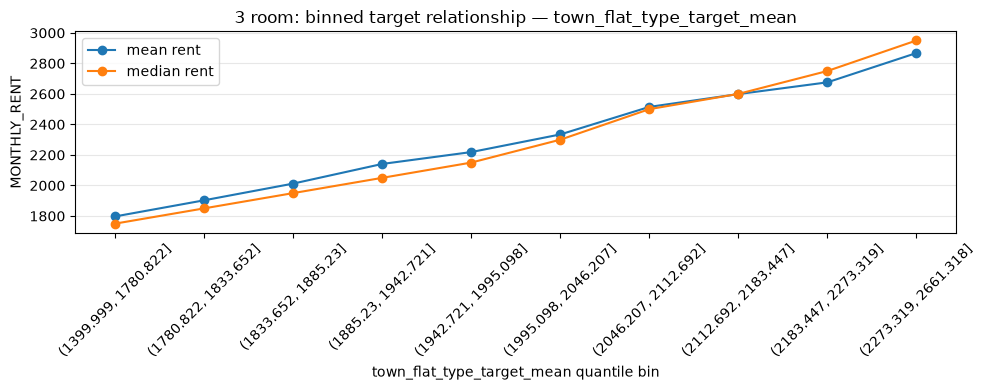

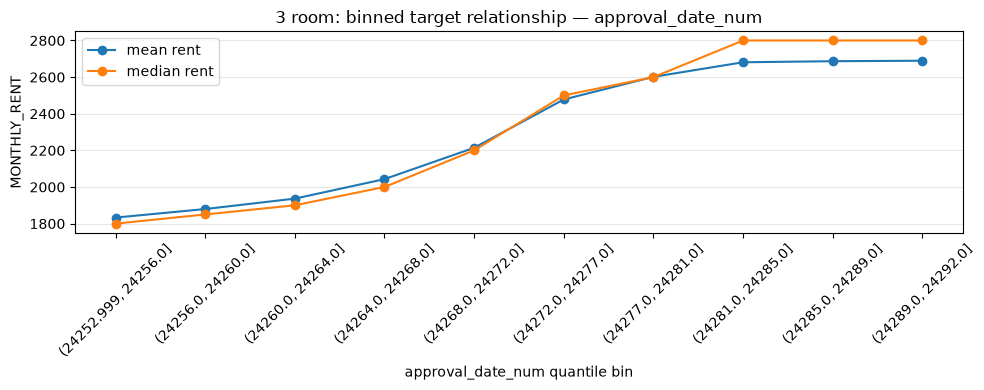

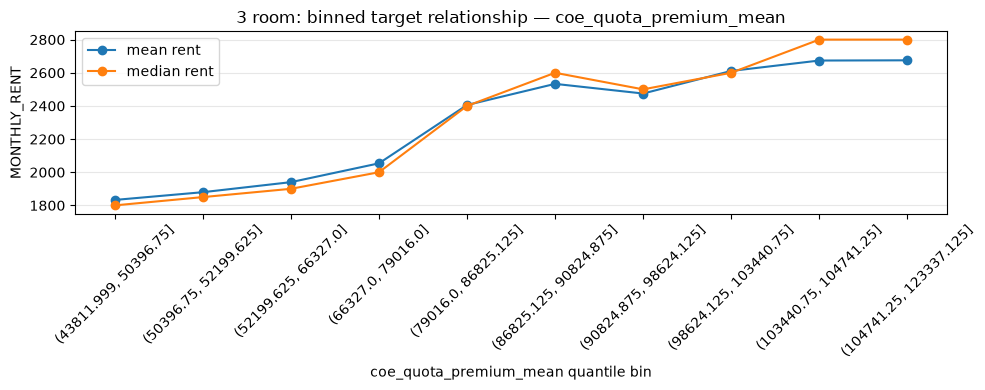

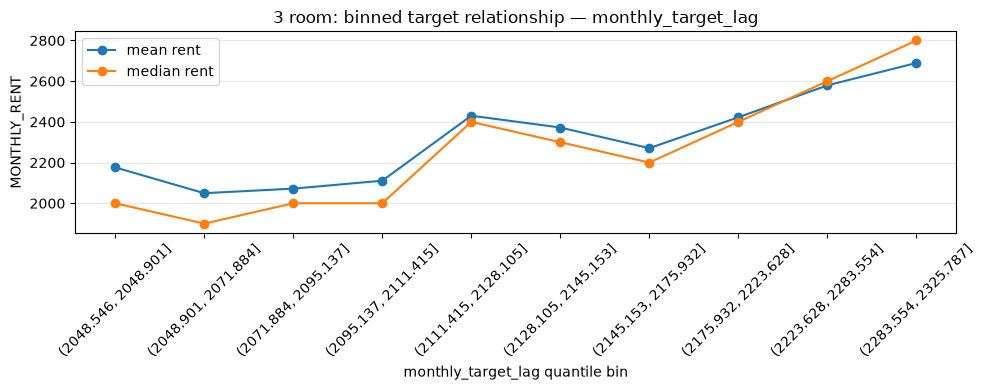

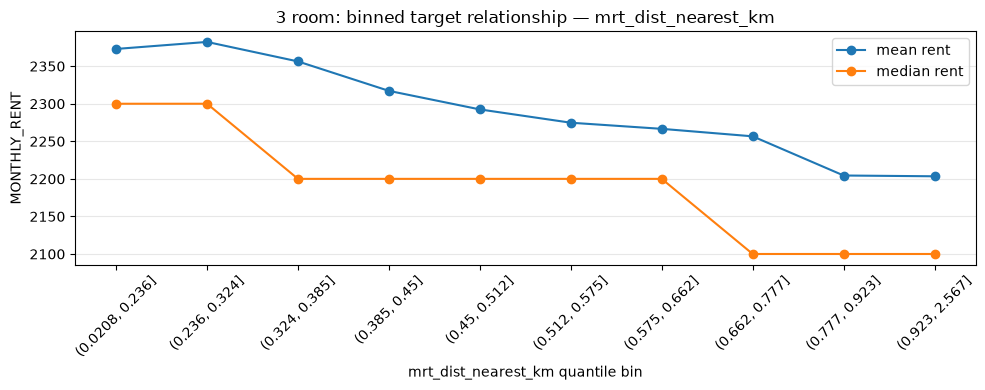


4 room: numeric nonlinear-dependence ranking


,feature,spearman,mutual_information,distance_correlation,abs_spearman
0,town_flat_type_target_mean,0.621442,0.359707,0.581911,0.621442
1,approval_date_num,0.606022,0.276216,0.588796,0.606022
2,coe_quota_premium_mean,0.568167,0.269168,0.559686,0.568167
3,monthly_target_lag,0.345377,0.238134,0.332593,0.345377
4,mrt_dist_nearest_km,-0.123816,0.095311,0.144291,0.123816
5,mall_dist_nearest_km,-0.069140,0.089932,0.080911,0.069140
6,YEAR_COMPLETED,0.108230,0.057037,0.159188,0.108230
7,MAX_FLOOR,0.172540,0.055826,0.222566,0.172540
8,FLOOR_AREA_SQM,-0.047032,0.027593,0.093888,0.047032
9,approval_month,0.058106,0.013521,0.052492,0.058106


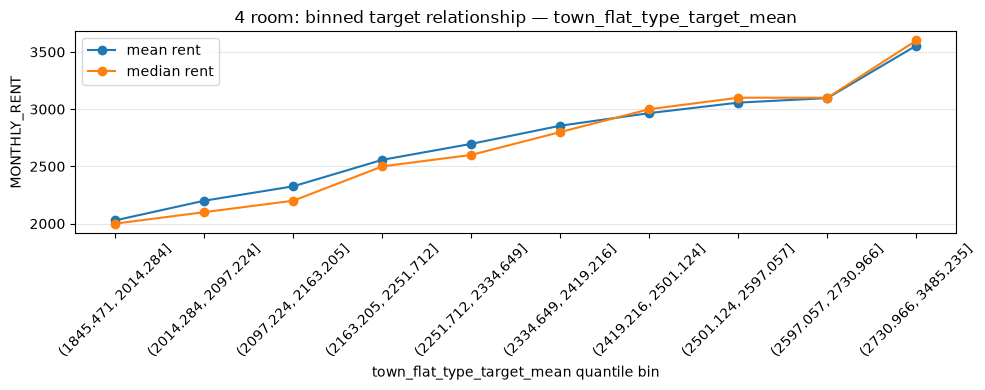

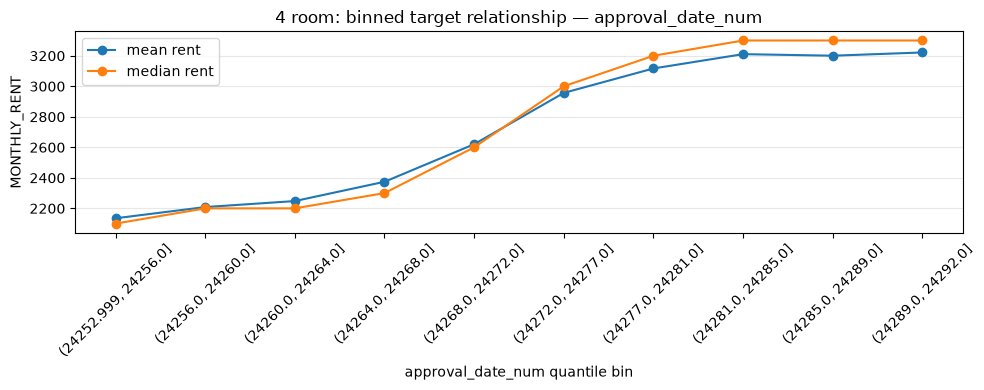

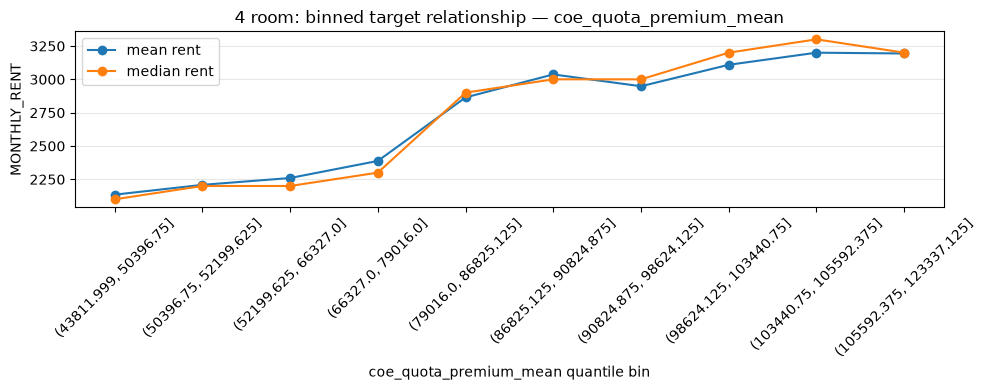

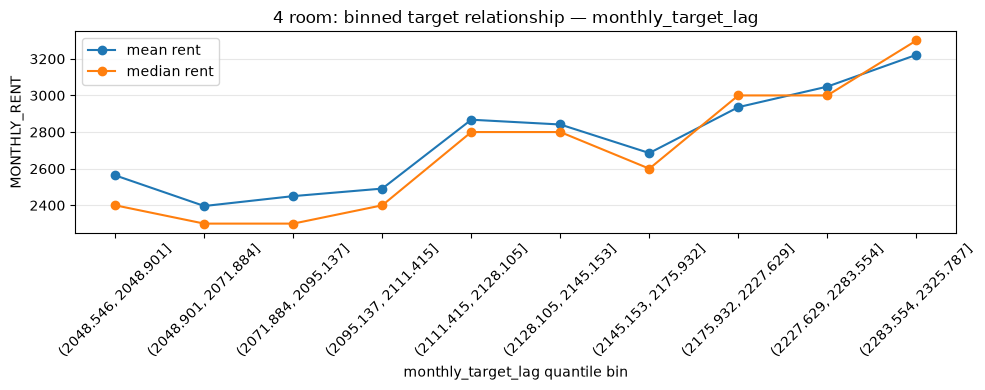

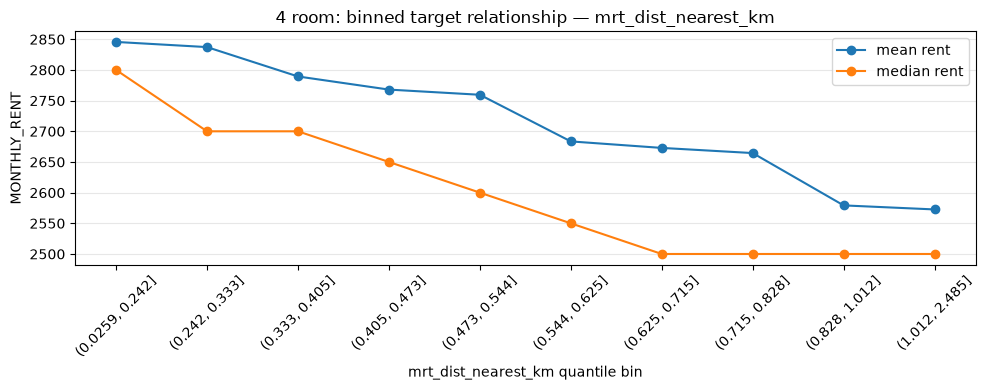


5 room: numeric nonlinear-dependence ranking


,feature,spearman,mutual_information,distance_correlation,abs_spearman
0,town_flat_type_target_mean,0.653809,0.394024,0.630331,0.653809
1,approval_date_num,0.642640,0.311081,0.614158,0.642640
2,coe_quota_premium_mean,0.604643,0.301541,0.592413,0.604643
3,monthly_target_lag,0.359414,0.258223,0.369990,0.359414
4,MAX_FLOOR,0.154837,0.075430,0.234980,0.154837
5,mall_dist_nearest_km,-0.013339,0.072174,0.044293,0.013339
6,mrt_dist_nearest_km,-0.108394,0.068984,0.114695,0.108394
7,YEAR_COMPLETED,0.021572,0.061244,0.125439,0.021572
8,FLOOR_AREA_SQM,-0.000620,0.035836,0.053789,0.000620
9,approval_month,0.064045,0.006871,0.071402,0.064045


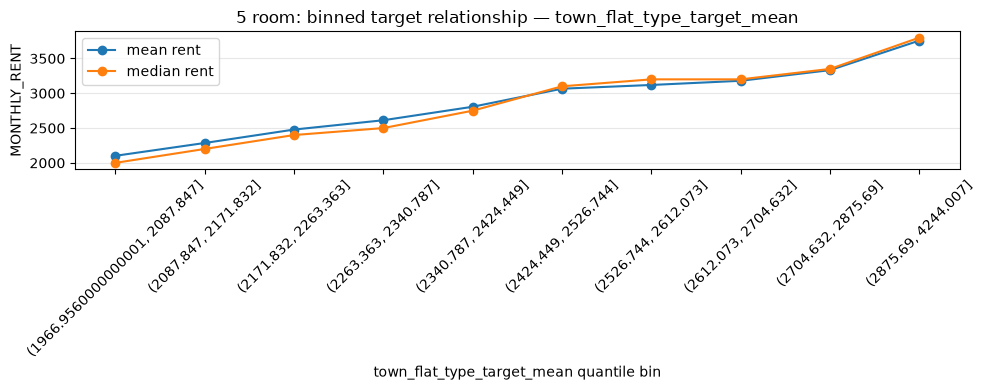

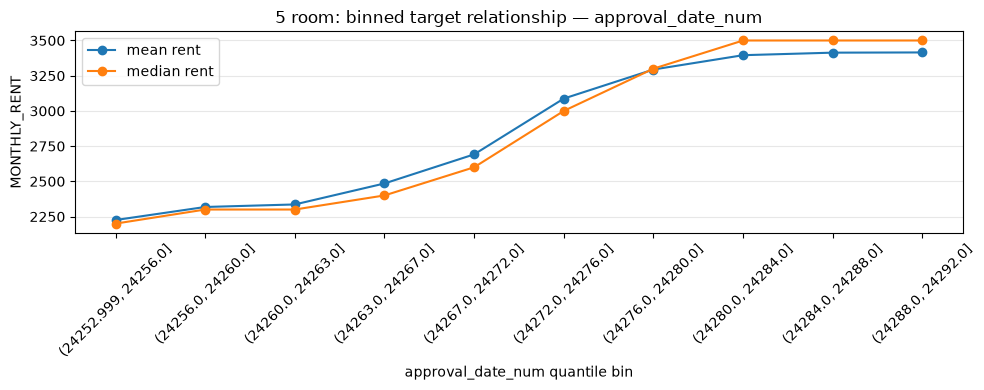

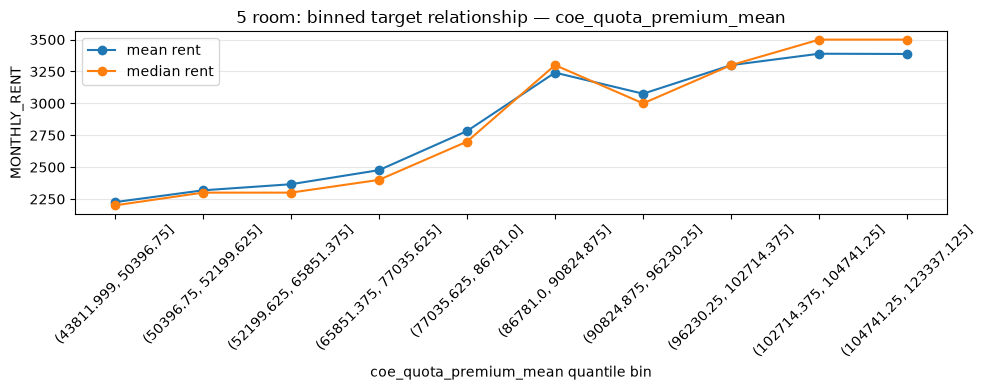

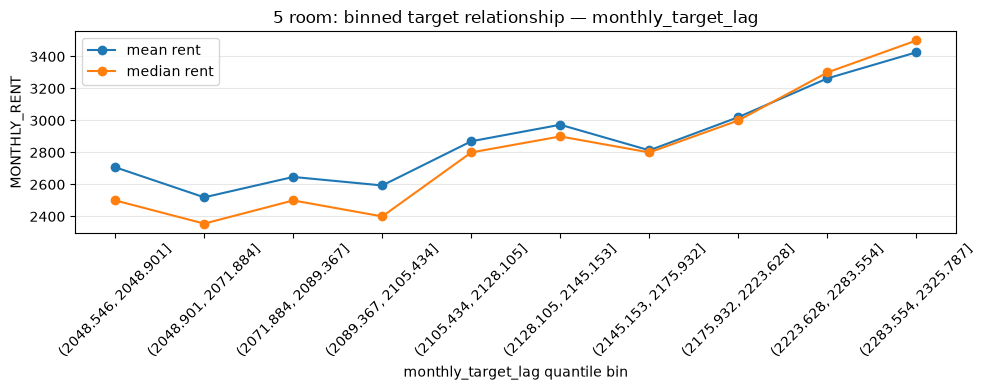

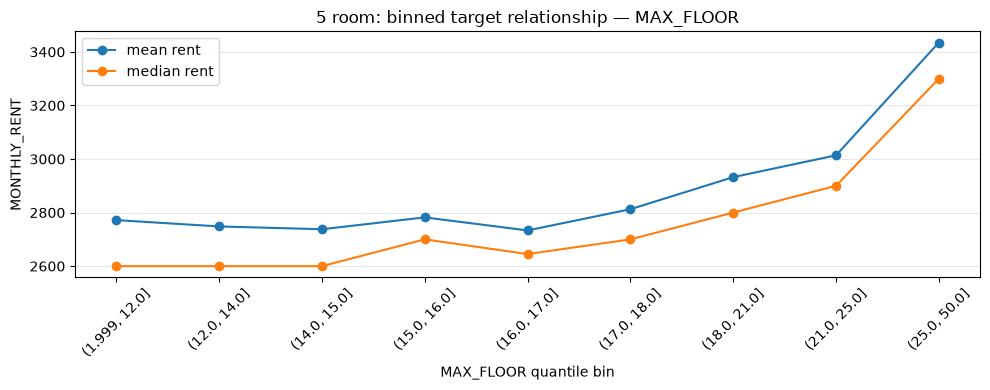


executive: numeric nonlinear-dependence ranking


,feature,spearman,mutual_information,distance_correlation,abs_spearman
0,coe_quota_premium_mean,0.612212,0.323122,0.627563,0.612212
1,approval_date_num,0.648549,0.321302,0.663193,0.648549
2,town_flat_type_target_mean,0.632056,0.277238,0.625261,0.632056
3,monthly_target_lag,0.375641,0.270796,0.368971,0.375641
4,mrt_dist_nearest_km,-0.080858,0.078797,0.083627,0.080858
5,mall_dist_nearest_km,-0.029198,0.060289,0.043541,0.029198
6,YEAR_COMPLETED,-0.057303,0.032874,0.049925,0.057303
7,FLOOR_AREA_SQM,0.056604,0.032299,0.055560,0.056604
8,MAX_FLOOR,0.018311,0.018982,0.064244,0.018311
9,approval_month,0.061752,0.005242,0.054682,0.061752


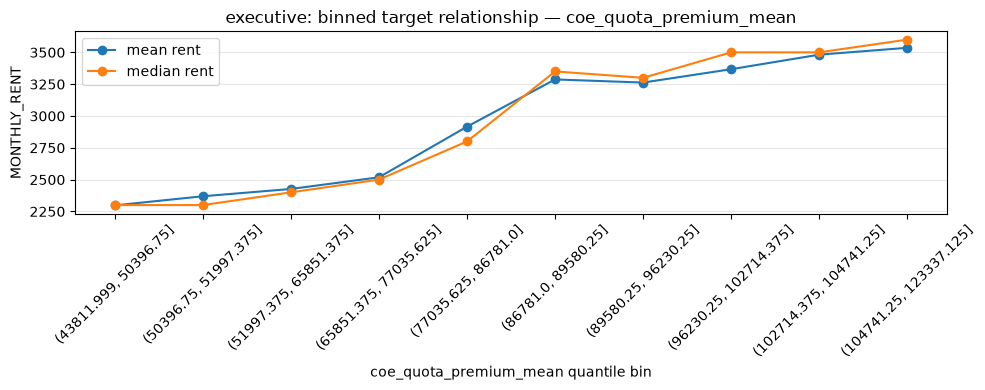

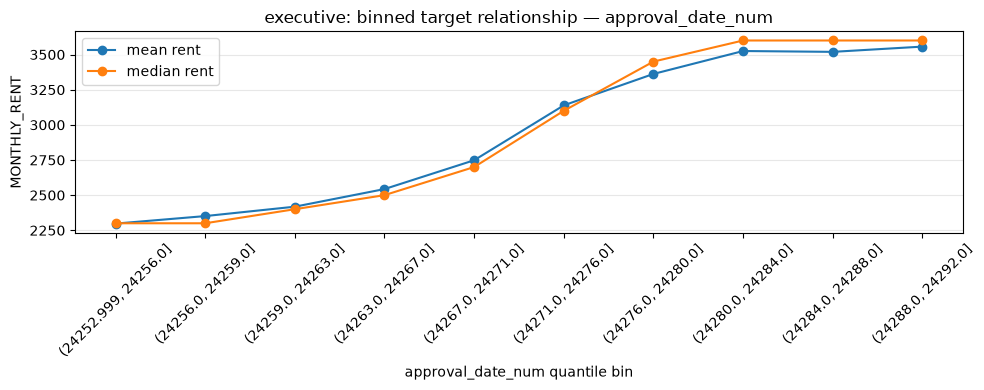

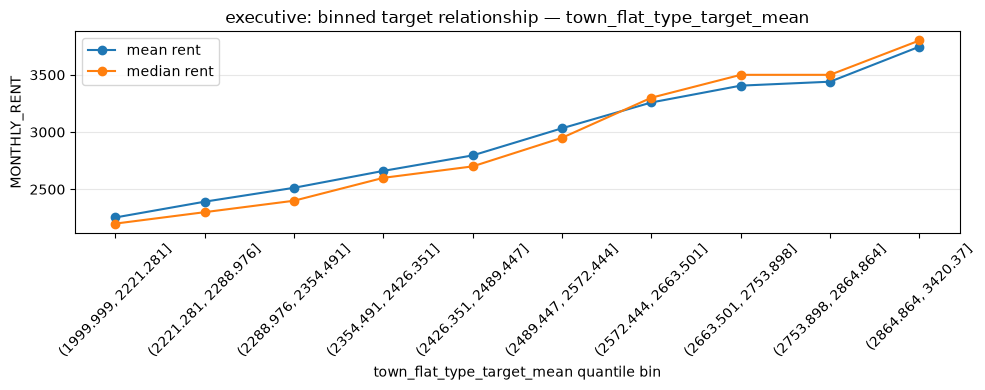

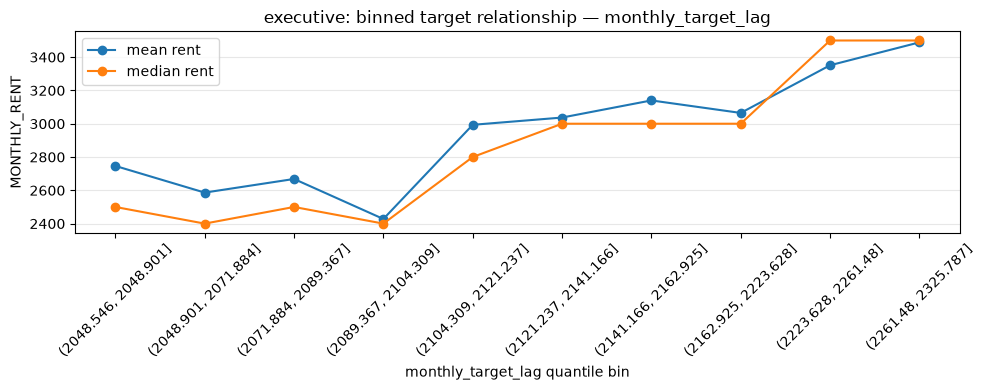

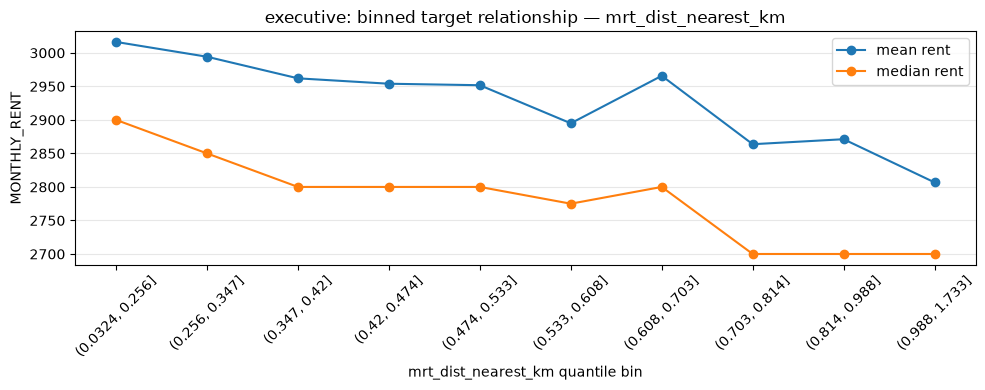

In [12]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_regression

numeric_feature_columns = fit_x.select_dtypes(include=np.number).columns.tolist()
NONLINEAR_SAMPLE_ROWS = 2_000
TOP_FEATURES_PER_SEGMENT = 5
def sampled_distance_correlation(x, y, max_rows=NONLINEAR_SAMPLE_ROWS, random_state=42):
    values = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(values) > max_rows: values = values.sample(max_rows, random_state=random_state)
    if len(values) < 3 or values.x.nunique() < 2 or values.y.nunique() < 2: return np.nan
    x_values, y_values = values.x.to_numpy(float), values.y.to_numpy(float)
    a = np.abs(x_values[:, None] - x_values[None, :]); b = np.abs(y_values[:, None] - y_values[None, :])
    a = a - a.mean(0)[None, :] - a.mean(1)[:, None] + a.mean()
    b = b - b.mean(0)[None, :] - b.mean(1)[:, None] + b.mean()
    dcov2, dvar_x2, dvar_y2 = (a * b).mean(), (a * a).mean(), (b * b).mean()
    return np.sqrt(max(dcov2, 0) / np.sqrt(max(dvar_x2, 1e-12) * max(dvar_y2, 1e-12)))

nonlinear_scores = {}
for flat_type in sorted(fit_x['FLAT_TYPE'].dropna().unique()):
    mask = fit_x.FLAT_TYPE.eq(flat_type)
    numeric = fit_x.loc[mask, numeric_feature_columns].copy()
    target = fit_y.loc[mask].reset_index(drop=True)
    numeric.index = target.index
    usable = [column for column in numeric if numeric[column].nunique(dropna=True) > 1]
    imputed = numeric[usable].fillna(numeric[usable].median())
    mi = mutual_info_regression(imputed, target, random_state=42)
    scores = pd.DataFrame({'feature': usable, 'spearman': [numeric[column].corr(target, method='spearman') for column in usable], 'mutual_information': mi, 'distance_correlation': [sampled_distance_correlation(numeric[column], target) for column in usable]})
    scores['abs_spearman'] = scores.spearman.abs()
    scores = scores.sort_values(['mutual_information', 'distance_correlation'], ascending=False).reset_index(drop=True)
    nonlinear_scores[flat_type] = scores
    print(f'\n{flat_type}: numeric nonlinear-dependence ranking')
    display(scores)
    for feature in scores.head(TOP_FEATURES_PER_SEGMENT).feature:
        plot_frame = pd.DataFrame({feature: numeric[feature], TARGET: target}).dropna()
        plot_frame['bin'] = pd.qcut(plot_frame[feature], q=min(10, plot_frame[feature].nunique()), duplicates='drop')
        binned = plot_frame.groupby('bin', observed=True).agg(mean_rent=(TARGET, 'mean'), median_rent=(TARGET, 'median'), rows=(TARGET, 'size')).reset_index()
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(binned['bin'].astype(str), binned.mean_rent, marker='o', label='mean rent')
        ax.plot(binned['bin'].astype(str), binned.median_rent, marker='o', label='median rent')
        ax.set(title=f'{flat_type}: binned target relationship — {feature}', xlabel=f'{feature} quantile bin', ylabel='MONTHLY_RENT')
        ax.tick_params(axis='x', rotation=45); ax.grid(axis='y', alpha=0.3); ax.legend(); fig.tight_layout(); plt.show()


In [13]:
def fit_tuned_predictor(segment_x, segment_y, segment_period, name):
    """Tune on a later inner period, then refit the best candidate on all segment rows."""
    unique_periods = np.sort(pd.Series(segment_period).unique())
    inner_cutoff = unique_periods[int(len(unique_periods) * 0.80)]
    hpo_train_mask = pd.Series(segment_period).reset_index(drop=True) < inner_cutoff
    if hpo_train_mask.sum() < 500 or (~hpo_train_mask).sum() < 100:
        raise ValueError(f'{name} has insufficient chronological rows for HPO.')
    train_data = segment_x.loc[hpo_train_mask].assign(**{TARGET: segment_y.loc[hpo_train_mask].to_numpy()})
    tuning_data = segment_x.loc[~hpo_train_mask].assign(**{TARGET: segment_y.loc[~hpo_train_mask].to_numpy()})
    predictor = TabularPredictor(
        label=TARGET, problem_type='regression', eval_metric='root_mean_squared_error',
        path=str(experiment_dir / 'ag_exp_11_flat_type_hpo' / RUN_ID / name),
    ).fit(
        train_data=train_data, tuning_data=tuning_data, hyperparameters=HPO_HYPERPARAMETERS,
        hyperparameter_tune_kwargs=HPO_KWARGS, fit_weighted_ensemble=False,
        presets=['medium_quality', 'ignore_text'], time_limit=HPO_TIME_LIMIT_PER_SEGMENT, verbosity=2,
    )
    best_model = predictor.model_best
    refit_map = predictor.refit_full(model=best_model, set_best_to_refit_full=True)
    return predictor, refit_map.get(best_model, best_model), inner_cutoff
def metrics(name, actual, prediction):
    return {'model':name, 'RMSE':mean_squared_error(actual,prediction)**0.5, 'MAE':mean_absolute_error(actual,prediction), 'R2':r2_score(actual,prediction)}

global_predictor, global_model, global_inner_cutoff = fit_tuned_predictor(fit_x, fit_y, raw_fit.period.reset_index(drop=True), 'global')
global_prediction = global_predictor.predict(valid_x, model=global_model).astype(float).to_numpy()
segmented_prediction = global_prediction.copy()
routing = pd.Series('global_fallback', index=valid_x.index, dtype=object)
segment_predictors = {}
for flat_type in eligible_flat_types:
    train_mask, valid_mask = fit_x.FLAT_TYPE.eq(flat_type), valid_x.FLAT_TYPE.eq(flat_type)
    if not valid_mask.any(): continue
    predictor, model_name, inner_cutoff = fit_tuned_predictor(
        fit_x.loc[train_mask].reset_index(drop=True), fit_y.loc[train_mask].reset_index(drop=True),
        raw_fit.loc[train_mask, 'period'].reset_index(drop=True), f'flat_type_{flat_type}'
    )
    segmented_prediction[valid_mask] = predictor.predict(valid_x.loc[valid_mask], model=model_name).astype(float).to_numpy()
    routing.loc[valid_mask] = f'flat_type_{flat_type}'
    segment_predictors[flat_type] = {'predictor': predictor, 'model': model_name, 'hpo_cutoff': inner_cutoff}

comparison = pd.DataFrame([metrics('Global AutoGluon', valid_y, global_prediction), metrics('Flat-type routed AutoGluon', valid_y, segmented_prediction)])
display(comparison.sort_values('RMSE'))
segment_metrics = pd.DataFrame([metrics(flat_type, valid_y.loc[valid_x.FLAT_TYPE.eq(flat_type)], segmented_prediction[valid_x.FLAT_TYPE.eq(flat_type)]) for flat_type in sorted(valid_x.FLAT_TYPE.dropna().unique())])
display(segment_metrics.sort_values('RMSE'))
display(routing.value_counts().rename_axis('route').reset_index(name='validation_rows'))
print(f'Global inner HPO cutoff: {global_inner_cutoff}; requested HPO trials: {HPO_TRIALS_PER_MODEL * len(HPO_HYPERPARAMETERS)} per routed model.')


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.2
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       4.77 GB / 16.00 GB (29.8%)
Disk Space Avail:   179.67 GB / 460.38 GB (39.0%)
Presets specified: ['medium_quality', 'ignore_text']
Beginning AutoGluon training ... Time limit = 900s
AutoGluon will save models to "/Users/metul/Desktop/KDDM-project/exploration/metul/ag_exp_11_flat_type_hpo/20260927_184954/global"
Train Data Rows:    94118
Train Data Columns: 18
Tuning Data Rows:    23870
Tuning Data Columns: 18
Label Column:       MONTHLY_RENT
Problem Type:       regression
Pre

,model,RMSE,MAE,R2
0,Global AutoGluon,471.447824,345.419599,0.485072
1,Flat-type routed AutoGluon,476.067943,352.306959,0.474930


,model,RMSE,MAE,R2
0,1 room,362.570500,322.291064,-0.128389
2,3 room,439.832669,332.843356,0.184450
1,2 room,442.636855,312.801575,0.048213
3,4 room,481.878623,359.867850,0.303761
4,5 room,492.310741,355.672140,0.319945
5,executive,591.632419,431.215633,0.109449


,route,validation_rows
0,flat_type_4 room,11678
1,flat_type_3 room,10584
2,flat_type_5 room,7270
3,flat_type_executive,1614
4,flat_type_2 room,856
5,global_fallback,10


Global inner HPO cutoff: 2023-09; requested HPO trials: 20 per routed model.


## Model-based nonlinear explanations: PDP/ICE and SHAP

PDP/ICE plots are computed directly from each routed AutoGluon model. SHAP uses a bounded permutation explainer, which works for any AutoGluon best model (including an ensemble) but is intentionally sampled because it is expensive.

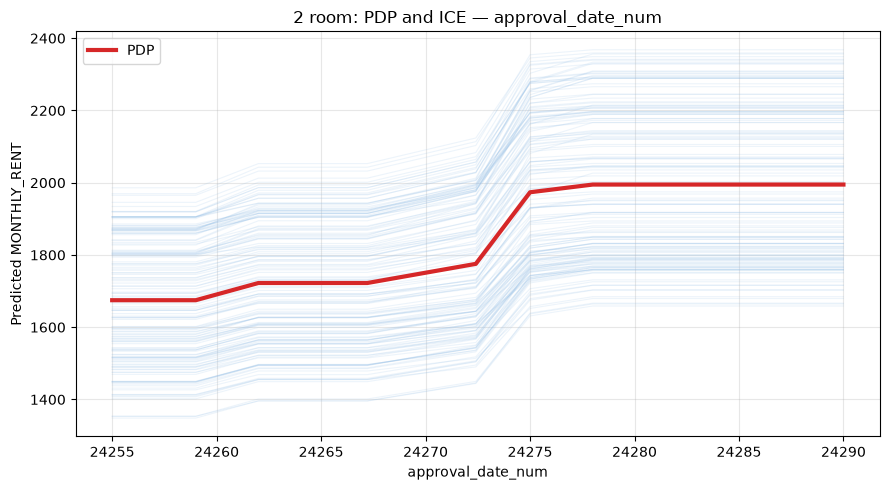

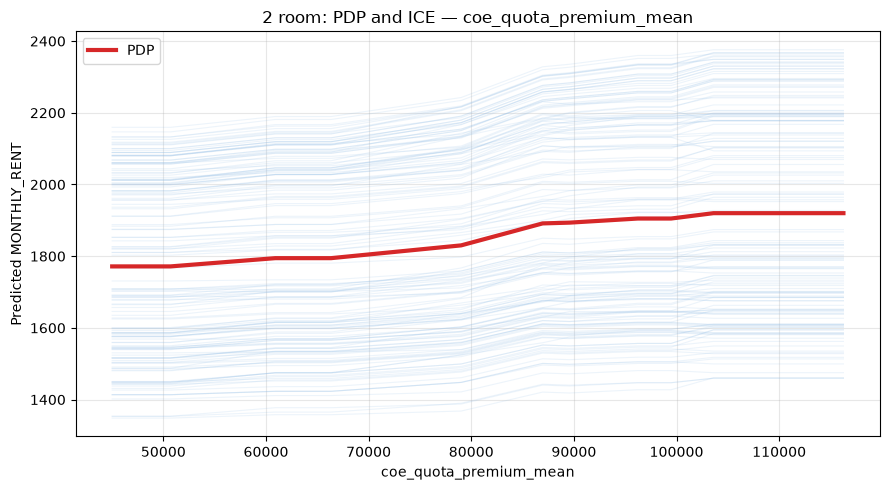

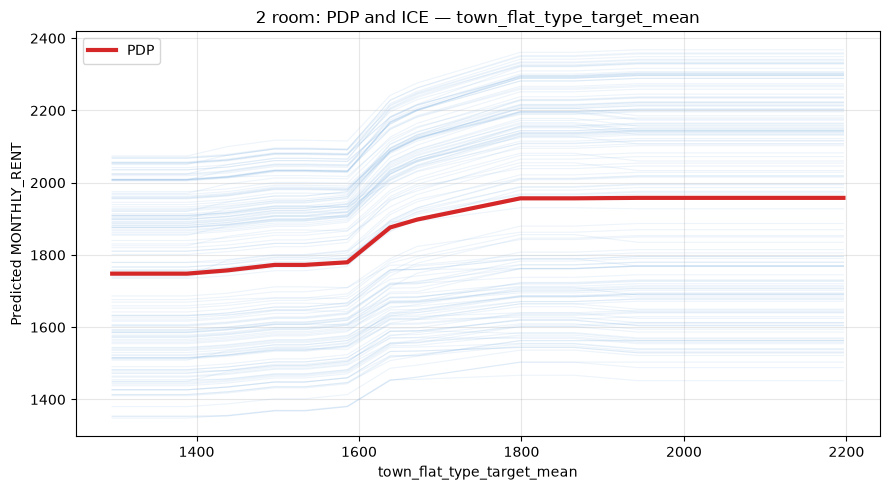

TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [14]:
import shap

TOP_MODEL_FEATURES = 3
ICE_ROWS = 150
SHAP_BACKGROUND_ROWS = 30
SHAP_EXPLAIN_ROWS = 80
feature_columns = fit_x.columns.tolist()

def plot_pdp_and_ice(predictor, model_name, segment_x, feature, flat_type):
    sample = segment_x.sample(min(ICE_ROWS, len(segment_x)), random_state=42).copy()
    grid = np.unique(np.quantile(sample[feature].dropna(), np.linspace(0.05, 0.95, 12)))
    if len(grid) < 2: return
    ice = []
    for value in grid:
        changed = sample.copy(); changed[feature] = value
        ice.append(predictor.predict(changed, model=model_name).astype(float).to_numpy())
    ice = np.asarray(ice)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(grid, ice, color='#8fbce6', alpha=0.16, linewidth=0.8)
    ax.plot(grid, ice.mean(axis=1), color='#d62728', linewidth=3, label='PDP')
    ax.set(title=f'{flat_type}: PDP and ICE — {feature}', xlabel=feature, ylabel='Predicted MONTHLY_RENT')
    ax.grid(alpha=0.3); ax.legend(); fig.tight_layout(); plt.show()

for flat_type, model_info in segment_predictors.items():
    segment_x = fit_x.loc[fit_x.FLAT_TYPE.eq(flat_type)].reset_index(drop=True)
    top_features = nonlinear_scores[flat_type].head(TOP_MODEL_FEATURES).feature.tolist()
    for feature in top_features: plot_pdp_and_ice(model_info['predictor'], model_info['model'], segment_x, feature, flat_type)
    background = segment_x.sample(min(SHAP_BACKGROUND_ROWS, len(segment_x)), random_state=42)
    explain_rows = segment_x.sample(min(SHAP_EXPLAIN_ROWS, len(segment_x)), random_state=7)
    def predict_frame(values, predictor=model_info['predictor'], model_name=model_info['model']):
        frame = values if isinstance(values, pd.DataFrame) else pd.DataFrame(values, columns=feature_columns)
        return predictor.predict(frame[feature_columns], model=model_name).astype(float).to_numpy()
    explainer = shap.Explainer(predict_frame, background, algorithm='permutation')
    shap_values = explainer(explain_rows, max_evals=2 * len(feature_columns) + 1)
    for feature in top_features:
        shap.plots.scatter(shap_values[:, feature], color=shap_values, show=False)
        plt.title(f'{flat_type}: SHAP dependence — {feature}')
        plt.tight_layout(); plt.show()
